# Finder Benchmark — leakage-controlled model comparison

This notebook benchmarks classical classifiers, LSTM, and GRU on the market crash labels used in `04 Benchmark.ipynb`.

**Leakage controls:**
- The final test period is selected chronologically by `TEST_CUTOFF` and is not used to fit models or update thresholds.
- A purge gap of `SEQ_LENGTH` observations is removed before the final test period so the sequence windows in adjacent partitions do not overlap.
- Missing-value imputation and neural-network scaling are fitted using training data only.
- The decision threshold is updated dynamically from the probability history and then used for final-test predictions and bootstrap confidence intervals.

Run cells from top to bottom. The input data files are expected under `Data/Indicators_crash/` and `Data/OHLCV/`, as in `04 Benchmark.ipynb`.

In [1]:
# Imports and reproducibility
from pathlib import Path
import os
import random
import warnings

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
)

try:
    import xgboost as xgb
except Exception as exc:
    xgb = None
    XGBOOST_IMPORT_ERROR = exc
else:
    XGBOOST_IMPORT_ERROR = None

try:
    import lightgbm as lgb
except Exception as exc:
    lgb = None
    LIGHTGBM_IMPORT_ERROR = exc
else:
    LIGHTGBM_IMPORT_ERROR = None

try:
    import tensorflow as tf
except Exception as exc:
    tf = None
    TF_IMPORT_ERROR = exc
else:
    TF_IMPORT_ERROR = None

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
if tf is not None:
    tf.random.set_seed(SEED)

print(f"TensorFlow available: {tf is not None}")
if tf is None:
    print(f"Neural models will be skipped. Import error: {TF_IMPORT_ERROR}")

TensorFlow available: True


## Configuration

Adjust `Market`, `DATA_DIR`, `TEST_CUTOFF`, and the sequence/training parameters for the experiment. The sequence length defaults to the value used in `04 Benchmark.ipynb`.

In [2]:
# Data configuration — paths are relative to the notebook's working directory.
Market = "CBU0"
DATA_DIR = Path("Data")

# Market OHLCV files joined as auxiliary features, matching 04 Benchmark.ipynb.
MARKET_LIST = ["SP500", "STOXX", "CAC", "DAX", "FTSE", "CBU0"]

# Sequence and chronological split settings
SEQ_LENGTH = 21
TEST_CUTOFF = pd.Timestamp("2025-03-01")
TRAIN_FRACTION = 1.00  # fraction of the purged pre-test samples allocated to the pre-validation era

# Set this to the number H of future observations used to construct each crash label.
# The default H=1 matches a next-row target. If crash_label uses an H-day forward-return
# window, set LABEL_HORIZON=H before running the notebook.
LABEL_HORIZON = 1
PURGE_GAP = SEQ_LENGTH + LABEL_HORIZON - 1

# Training settings
EPOCHS = 100
BATCH_SIZE = 32
RECURRENT_UNITS = 40
DENSE_UNITS = 20
DROPOUT_1 = 0.30
DROPOUT_2 = 0.30
LEARNING_RATE = 0.0005
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.20
EARLY_STOP_PATIENCE = 15
LR_PATIENCE = 4
LR_FACTOR = 0.5
MIN_LR = 1e-6

# Bootstrap confidence interval settings; lower this for a faster smoke test.
BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_BLOCK_SIZE = 20

SAVE_RESULTS = True
OUTPUT_DIR = Path("Results/Benchmark_Outputs/With_news_v2")

## Read and align crash labels, indicators, and other-market OHLCV

The target label is taken from the crash-label file. Other label-file columns (for example, future-return or threshold metadata) are explicitly excluded from model features to prevent target-derived information from entering `X`.

In [3]:
from sklearn.decomposition import PCA

news_embeddings_df = pd.read_csv(f'Data/{Market}_daily_news_embeddings.csv', parse_dates=['date'])
embedding_cols = [col for col in news_embeddings_df.columns if col != 'date']

components = 10  # Number of PCA components to keep

# Select only embedding/features columns
X = news_embeddings_df[embedding_cols].values

# PCA
pca = PCA(n_components=components, random_state=42)

X_pca = pca.fit_transform(X)

# Create DataFrame
pca_cols = [f"news_pca_{i}" for i in range(components)]

news_pca_df = pd.DataFrame(
    X_pca,
    columns=pca_cols,
    index=news_embeddings_df.index
)

# Keep date if needed
news_pca_df["date"] = news_embeddings_df["date"].values

print("Original shape:", X.shape)
print("PCA shape:", X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

Original shape: (7177, 768)
PCA shape: (7177, 10)
Explained variance: 0.6473617628223991


In [ ]:
label_path = DATA_DIR / "Indicators_crash" / f"{Market}_df_Crash_Label.csv"
indicator_path = DATA_DIR / "Indicators_crash" / f"{Market}_df_Indicators.csv"

for required_path in (label_path, indicator_path):
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required input file not found: {required_path.resolve()}\n"
            "Set DATA_DIR to the folder containing Data/Indicators_crash and Data/OHLCV."
        )

crash_labels = pd.read_csv(label_path)
indicators = pd.read_csv(indicator_path)

if "date" not in crash_labels.columns:
    raise KeyError(f"Expected a 'date' column in {label_path}")
if "crash_label" not in crash_labels.columns:
    raise KeyError(f"Expected a 'crash_label' column in {label_path}")
if "Date" not in indicators.columns:
    raise KeyError(f"Expected a 'Date' column in {indicator_path}")

crash_labels["date"] = pd.to_datetime(crash_labels["date"], errors="coerce")
indicators["Date"] = pd.to_datetime(indicators["Date"], errors="coerce")
crash_labels["crash_label"] = pd.to_numeric(crash_labels["crash_label"], errors="coerce")

# Invalid target rows are removed rather than forward-filling labels.
crash_labels = (
    crash_labels.dropna(subset=["date", "crash_label"])
    .sort_values("date")
    .drop_duplicates(subset=["date"], keep="last")
    .reset_index(drop=True)
)
indicators = (
    indicators.dropna(subset=["Date"])
    .sort_values("Date")
    .drop_duplicates(subset=["Date"], keep="last")
    .reset_index(drop=True)
)

# Load and merge auxiliary OHLCV files for the other markets. The joins are left joins
# so missing market dates can be handled by train-fitted imputation rather than dropping rows.
OHLCV_df_list = []
missing_ohlcv_files = []
for other_market in MARKET_LIST:
    if other_market == Market:
        continue
    ohlcv_path = DATA_DIR / "OHLCV" / f"{other_market}_df_OHLCV.csv"
    if not ohlcv_path.exists():
        missing_ohlcv_files.append(str(ohlcv_path))
        continue

    other_df = pd.read_csv(ohlcv_path)
    if "Date" not in other_df.columns:
        raise KeyError(f"Expected a 'Date' column in {ohlcv_path}")
    other_df["Date"] = pd.to_datetime(other_df["Date"], errors="coerce")
    other_df = other_df.dropna(subset=["Date"]).drop_duplicates(subset=["Date"], keep="last")
    other_df = other_df.rename(
        columns={col: f"{col}_{other_market}" for col in other_df.columns if col != "Date"}
    )
    OHLCV_df_list.append(other_df)

if missing_ohlcv_files:
    print("Warning: auxiliary OHLCV files not found; continuing without these markets:")
    for missing_path in missing_ohlcv_files:
        print(f"  - {missing_path}")

if OHLCV_df_list:
    OHLCV_df = OHLCV_df_list[0]
    for other_df in OHLCV_df_list[1:]:
        OHLCV_df = OHLCV_df.merge(other_df, on="Date", how="outer", validate="one_to_one")
    OHLCV_df = OHLCV_df.sort_values("Date").reset_index(drop=True)
    indicators = indicators.merge(OHLCV_df, on="Date", how="left", validate="one_to_one")

# # Convert indicators date column to datetime
# indicators['date'] = pd.to_datetime(indicators['Date'])

# Merge news embeddings with indicators on date
indicators = indicators.merge(
    news_pca_df,
    left_on='Date',
    right_on='date',
    how='left'
)

# Fill missing embeddings (days without news) with zeros
embedding_cols_list = [col for col in indicators.columns if col.startswith('news_pca_')]
indicators[embedding_cols_list] = indicators[embedding_cols_list].fillna(0)
indicators = indicators.drop(columns=['date'])  # Drop the redundant 'date' column after merge

# Preserve every label column name so all label-file metadata is excluded from X.
label_metadata_columns = set(crash_labels.columns) - {"date"}
merged_df = indicators.merge(
    crash_labels[["date", "crash_label"]],
    left_on="Date",
    right_on="date",
    how="inner",
    validate="one_to_one",
) 

merged_df = merged_df.sort_values("date").drop_duplicates(subset=["date"], keep="last").reset_index(drop=True)

if merged_df.empty:
    raise ValueError("No rows remain after aligning indicators and crash labels. Check the dates in the CSV files.")

print(f"Merged dataframe shape: {merged_df.shape}")
print(f"Date range: {merged_df['date'].min().date()} to {merged_df['date'].max().date()}")
print("Crash-label distribution:")
print(merged_df["crash_label"].value_counts(dropna=False).sort_index())

,Date,close,high,low,open,volume,return,sma20,sma50,sma200,...,news_pca_1,news_pca_2,news_pca_3,news_pca_4,news_pca_5,news_pca_6,news_pca_7,news_pca_8,news_pca_9,date
0,2017-03-02,136.350,136.630000,134.450000,136.630000,4703.0,-0.002234,137.19550,136.7607,141.227300,...,-3.257471,4.579819,-2.431263,-0.129790,0.632210,0.073752,-2.241868,0.726189,-1.824106,2017-03-02
1,2017-03-03,136.205,136.205002,136.205002,136.205002,0.0,-0.001064,137.15475,136.7889,141.203200,...,1.389908,0.071318,-0.134395,0.128453,-1.119001,-1.833957,0.584590,0.617093,-0.719733,2017-03-03
2,2017-03-06,136.440,136.440002,136.440002,136.440002,0.0,0.001724,137.12050,136.8147,141.180200,...,-9.104999,-0.789156,-2.781252,2.061284,-0.078362,-3.038534,1.197902,-1.479959,0.603865,2017-03-06
3,2017-03-07,136.275,136.274994,136.274994,136.274994,0.0,-0.001210,137.05875,136.8369,141.157575,...,-3.796353,-1.298361,0.956141,0.712777,1.459013,2.703543,-1.908158,-1.661416,-1.932289,2017-03-07
4,2017-03-08,135.705,135.630000,135.630000,135.630000,1467.0,-0.004191,136.94425,136.8453,141.130725,...,-3.058855,5.254254,4.025842,-2.657863,1.480503,2.559755,-1.722480,-1.084296,2.038783,2017-03-08


,Date,close,high,low,open,volume,return,sma20,sma50,sma200,...,news_pca_3,news_pca_4,news_pca_5,news_pca_6,news_pca_7,news_pca_8,news_pca_9,date_x,date_y,crash_label
0,2018-07-04,137.285,137.87,137.29,137.58,870.0,0.000109,136.52325,135.8207,137.744900,...,-4.639677,-1.171218,-0.469038,3.858578,0.494118,-1.047939,0.273759,2018-07-04,2018-07-04,0.0
1,2018-07-05,137.440,137.44,137.08,137.18,27345.0,0.001128,136.60775,135.8700,137.726300,...,-3.650583,0.360085,-0.868745,1.606917,-1.054125,0.301133,-0.007057,2018-07-05,2018-07-05,0.0
2,2018-07-06,137.380,137.56,137.35,137.35,2939.0,-0.000437,136.66775,135.9226,137.707350,...,-3.619606,-1.058869,-0.206916,2.061303,-0.290531,-0.712631,-0.724701,2018-07-06,2018-07-06,0.0
3,2018-07-09,137.190,137.23,137.12,137.23,3055.0,-0.001384,136.73275,135.9662,137.688550,...,-2.126940,1.851069,-1.224018,-1.791658,3.358190,-0.949374,1.471421,2018-07-09,2018-07-09,0.0
4,2018-07-10,137.045,137.09,137.02,137.05,4714.0,-0.001057,136.79650,135.9992,137.669025,...,-4.311392,-1.084383,-0.312777,3.609015,0.226931,-0.971742,0.353045,2018-07-10,2018-07-10,0.0


KeyError: 'date'

## Create sequence samples and leakage-controlled splits

Each sample uses the preceding `SEQ_LENGTH` rows of features to predict the label on the next row. The sample's timestamp is therefore the **target date**, not the last feature date.

The purge removes the most recent pre-test samples so the input windows do not overlap with the final test period. `PURGE_GAP = SEQ_LENGTH + LABEL_HORIZON - 1` protects against overlap in input windows and, when configured correctly, a forward-looking target window. Set `LABEL_HORIZON` to the actual look-ahead used to generate `crash_label`; that label-generation horizon is not documented in `04 Benchmark.ipynb` itself.

In [4]:
# Build the raw feature matrix. All columns from the crash-label CSV (except its date key)
# are excluded, including min_future_logret/crash_threshold if those columns exist.
exclude_columns = {"Date", "date"} | label_metadata_columns
feature_columns = [col for col in merged_df.columns if col not in exclude_columns]
if not feature_columns:
    raise ValueError("No feature columns remain after excluding date and label metadata columns.")

X_raw_all = merged_df[feature_columns].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
X_raw_all[~np.isfinite(X_raw_all)] = np.nan

y_raw_all = merged_df["crash_label"].to_numpy(dtype=np.int32)
dates_raw_all = pd.to_datetime(merged_df["date"]).to_numpy()

unique_labels = set(np.unique(y_raw_all).tolist())
if not unique_labels.issubset({0, 1}) or len(unique_labels) < 2:
    raise ValueError(
        f"Expected binary crash_label values 0 and 1 in the aligned dataset; found {sorted(unique_labels)}."
    )
if len(X_raw_all) <= SEQ_LENGTH + PURGE_GAP + 2:
    raise ValueError("Not enough aligned rows for the configured sequence length and purge gap.")

# Sample i uses X_raw_all[i:i + SEQ_LENGTH] and predicts y_raw_all[i + SEQ_LENGTH].
n_samples_total = len(X_raw_all) - SEQ_LENGTH
sample_start_indices = np.arange(n_samples_total)
dates_seq_all = pd.to_datetime(dates_raw_all[SEQ_LENGTH:])
y_seq_all = y_raw_all[SEQ_LENGTH:]

pre_test_sample_indices = np.flatnonzero(dates_seq_all < TEST_CUTOFF)
test_sample_indices = np.flatnonzero(dates_seq_all >= TEST_CUTOFF)
if len(test_sample_indices) == 0:
    raise ValueError(
        f"No sequence targets fall on or after TEST_CUTOFF={TEST_CUTOFF.date()}. "
        "Choose a cutoff within the available data range."
    )
if len(pre_test_sample_indices) <= PURGE_GAP + 2:
    raise ValueError("Not enough pre-test samples remain after applying the test-boundary purge.")

# Remove the final PURGE_GAP pre-test samples so their input windows cannot overlap
# the first test input window. Keep final test samples untouched.
if PURGE_GAP > 0:
    development_sample_indices = pre_test_sample_indices[:-PURGE_GAP]
else:
    development_sample_indices = pre_test_sample_indices.copy()

if len(development_sample_indices) < 10:
    raise ValueError("Too few development samples remain after purging the final test boundary.")

# Use a strictly train/test split without a validation set.
train_sample_indices = development_sample_indices.copy()
if len(train_sample_indices) == 0:
    raise ValueError("The training set is empty after purging.")

# Fit the imputation values using only raw feature rows appearing in the training windows.
train_raw_end = int(train_sample_indices.max() + SEQ_LENGTH)  # exclusive endpoint
X_train_raw_rows = X_raw_all[:train_raw_end]
feature_has_train_values = np.isfinite(X_train_raw_rows).any(axis=0)
if not feature_has_train_values.any():
    raise ValueError("All feature columns are missing in the training period.")

retained_feature_columns = [
    col for col, keep in zip(feature_columns, feature_has_train_values) if keep
]
X_raw = X_raw_all[:, feature_has_train_values]
train_medians = np.nanmedian(X_raw[:train_raw_end], axis=0)
# Numerical guard: retained columns should have a median, but protect against degenerate inputs.
train_medians = np.where(np.isfinite(train_medians), train_medians, 0.0)
X_raw = np.where(np.isfinite(X_raw), X_raw, train_medians.reshape(1, -1))

# Materialize fixed-length sequences only after fitting train-only imputation values.
X_seq_all = np.stack(
    [X_raw[i:i + SEQ_LENGTH] for i in range(n_samples_total)],
    axis=0,
).astype(np.float32)

X_train = X_seq_all[train_sample_indices]
y_train = y_seq_all[train_sample_indices]
dates_train = dates_seq_all[train_sample_indices]

X_test = X_seq_all[test_sample_indices]
y_test = y_seq_all[test_sample_indices]
dates_test = dates_seq_all[test_sample_indices]

# A train-only scaler for recurrent models; flattened classical models use their own Pipeline scaler.
sequence_scaler = StandardScaler()
sequence_scaler.fit(X_train.reshape(-1, X_train.shape[-1]))

def scale_sequences(X, scaler):
    """Transform a (samples, timesteps, features) tensor with a train-fitted scaler."""
    original_shape = X.shape
    return scaler.transform(X.reshape(-1, original_shape[-1])).reshape(original_shape).astype(np.float32)

X_train_scaled = scale_sequences(X_train, sequence_scaler)
X_test_scaled = scale_sequences(X_test, sequence_scaler)

print("\nDATA SPLIT SUMMARY")
print("=" * 72)
print(f"Sequence length:       {SEQ_LENGTH}")
print(f"Original features:     {len(feature_columns)}")
print(f"Retained features:     {len(retained_feature_columns)}")
print(f"Purge gap:             {PURGE_GAP} samples")
print(f"Training sequences:    {X_train.shape} | positives={int(y_train.sum())}")
print(f"Final test sequences:  {X_test.shape} | positives={int(y_test.sum())}")
print(f"Training dates:        {pd.Timestamp(dates_train.min()).date()} -> {pd.Timestamp(dates_train.max()).date()}")
print(f"Test dates:            {pd.Timestamp(dates_test.min()).date()} -> {pd.Timestamp(dates_test.max()).date()}")

# Explicit safeguards: chronological order and the required purge gaps.
assert dates_train.max() < dates_test.min()
assert len(train_sample_indices) > 0 and len(test_sample_indices) > 0
assert train_sample_indices.max() + PURGE_GAP < test_sample_indices.min()
print("\nLeakage checks passed: chronological train/test partitions and purge gap are in place.")



DATA SPLIT SUMMARY
Sequence length:       21
Original features:     93
Retained features:     93
Purge gap:             21 samples
Training sequences:    (1641, 21, 93) | positives=97
Final test sequences:  (377, 21, 93) | positives=19
Training dates:        2018-08-02 -> 2025-01-30
Test dates:            2025-03-03 -> 2026-08-27

Leakage checks passed: chronological train/test partitions and purge gap are in place.


## Metrics, threshold selection, and block-bootstrap confidence intervals

A dynamic threshold is updated sequentially from the observed probability history, then used to produce test predictions. The bootstrap resamples paired test observations in contiguous blocks and does not retune the threshold using separate validation labels.

In [5]:
import numpy as np

def dynamic_thresholding(
    probabilities,
    labels,
    initial_threshold=0.5,
):

    probabilities = np.asarray(probabilities, dtype=float)
    labels = np.asarray(labels, dtype=int)

    if probabilities.ndim != 1 or labels.ndim != 1:
        raise ValueError("Inputs must be one-dimensional.")

    if len(probabilities) != len(labels):
        raise ValueError("Probabilities and labels must have equal lengths.")

    if not np.all(np.isfinite(probabilities)):
        raise ValueError("Probabilities must contain finite values.")

    if not np.all(np.isin(labels, [0, 1])):
        raise ValueError("Labels must be binary (0 or 1).")

    n = len(probabilities)

    thresholds = np.empty(n)
    predictions = np.empty(n, dtype=int)

    eta_prev = initial_threshold

    hist_probs = []
    hist_labels = []

    for i in range(n):

        m = len(hist_labels)

        # Update threshold using historical observations only
        if m > 1 and sum(hist_labels) > 0:

            hp = np.asarray(hist_probs)
            hl = np.asarray(hist_labels)

            # Sort historical probabilities once
            order = np.argsort(hp)

            sorted_probs = hp[order]
            sorted_labels = hl[order]

            # Candidate thresholds
            candidates = np.unique(
                np.concatenate((
                    sorted_probs,
                    [0.0, 1.0, eta_prev]
                ))
            )

            # Number of predicted positives for each threshold
            positions = np.searchsorted(
                sorted_probs,
                candidates,
                side="left"
            )

            predicted_positive = m - positions

            # Number of true positives for each threshold
            suffix_tp = np.concatenate((
                np.cumsum(sorted_labels[::-1])[::-1],
                [0]
            ))

            true_positive = suffix_tp[positions]

            # Actual number of positive observations
            actual_positive = np.sum(sorted_labels)

            # Vectorized F1 calculation
            denominator = (
                predicted_positive + actual_positive
            )

            f1_scores = np.divide(
                2.0 * true_positive,
                denominator,
                out=np.zeros(len(candidates)),
                where=denominator != 0
            )

            # Select threshold maximizing historical F1
            best_idx = np.argmax(f1_scores)

            eta_prev = candidates[best_idx]

        # Apply threshold to current observation
        thresholds[i] = eta_prev

        predictions[i] = int(
            probabilities[i] >= eta_prev
        )

        # Add current observation to history AFTER prediction
        hist_probs.append(probabilities[i])
        hist_labels.append(labels[i])

    return thresholds, predictions


def compute_metrics(
    y_true,
    probs,
    preds
):

    return {

        "ROC_AUC":
            roc_auc_score(
                y_true,
                probs
            ),

        "AP":
            average_precision_score(
                y_true,
                probs
            ),

        "Precision":
            precision_score(
                y_true,
                preds,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                preds,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                preds,
                zero_division=0
            ),

        "MCC":
            matthews_corrcoef(
                y_true,
                preds
            )
    }


import numpy as np
import warnings

def bootstrap_confidence_intervals(
    y_true,
    probs,
    threshold=0.5,
    block_size=20,
    n_bootstrap=2000,
    random_state=42
):

    y_true = np.asarray(y_true)
    probs = np.asarray(probs)

    # Validate inputs
    n = len(y_true)

    if n != len(probs):
        raise ValueError("y_true and probs must have the same length.")

    if not 0.0 <= threshold <= 1.0:
        raise ValueError("threshold must be between 0 and 1.")

    if not 1 <= block_size <= n:
        raise ValueError("block_size must be between 1 and len(y_true).")

    if n_bootstrap <= 0:
        raise ValueError("n_bootstrap must be positive.")

    # Initialize random generator
    rng = np.random.default_rng(random_state)

    # Initialize metric storage
    metrics_storage = {
        "ROC_AUC": [],
        "AP": [],
        "Precision": [],
        "Recall": [],
        "F1": [],
        "MCC": []
    }

    successful = 0
    failed = 0

    # Valid starting positions for blocks
    starts = np.arange(n - block_size + 1)

    # Number of blocks required to reach n observations
    n_blocks = int(np.ceil(n / block_size))

    for _ in range(n_bootstrap):
        # Randomly select block starting positions
        selected_starts = rng.choice(
            starts,
            size=n_blocks,
            replace=True
        )

        # Construct bootstrap indices
        idx = np.concatenate([
            np.arange(start, start + block_size)
            for start in selected_starts
        ])[:n]

        # Generate bootstrap dataset
        yb = y_true[idx]
        pb = probs[idx]

        try:
            # Dynamic thresholding using the model's final threshold as the starting point
            _, predb = dynamic_thresholding(
                pb,
                yb,
                initial_threshold=threshold,
            )

            # Calculate metrics
            m = compute_metrics(
                yb,
                pb,
                predb
            )

            # Store metrics
            for k in metrics_storage:
                value = m[k]

                if np.isfinite(value):
                    metrics_storage[k].append(value)

            successful += 1

        except Exception as e:
            failed += 1

            # Print only the first few errors
            if failed <= 5:
                print(f"Bootstrap iteration failed: {e}")

    # Report bootstrap performance
    print(f"Successful iterations: {successful}")
    print(f"Failed iterations: {failed}")

    # Calculate confidence intervals
    ci = {}

    for metric, values in metrics_storage.items():
        if len(values) < 100:
            warnings.warn(
                f"Only {len(values)} valid values for {metric}. "
                "Confidence interval may be unreliable."
            )

            if len(values) == 0:
                ci[f"{metric}_LOW"] = np.nan
                ci[f"{metric}_HIGH"] = np.nan
                continue

        ci[f"{metric}_LOW"] = np.percentile(values, 2.5)
        ci[f"{metric}_HIGH"] = np.percentile(values, 97.5)

    return ci

## Classical models and recurrent architectures

The LSTM and GRU use the same configurable architecture as the recurrent benchmark in `04 Benchmark.ipynb`: recurrent layer, dropout, dense ReLU layer, dropout, and sigmoid output. Input dimensions are derived from the observed sequence and feature counts rather than hard-coded.

In [6]:
def get_classical_models():
    models = {
        "Logistic": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                penalty="l2", max_iter=5000, class_weight="balanced", random_state=SEED
            )),
        ]),
        "ElasticNet": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                penalty="elasticnet", solver="saga", l1_ratio=0.5,
                max_iter=5000, class_weight="balanced", random_state=SEED
            )),
        ]),
        "RandomForest": RandomForestClassifier(
            n_estimators=500, max_depth=12, class_weight="balanced_subsample",
            n_jobs=-1, random_state=SEED
        ),
        "MLP": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(
                hidden_layer_sizes=(512, 256), max_iter=1000,
                early_stopping=True, random_state=SEED
            )),
        ]),
    }

    if xgb is not None:
        models["XGBoost"] = xgb.XGBClassifier(
            objective="binary:logistic", n_estimators=500, max_depth=4,
            learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
            eval_metric="aucpr", random_state=SEED, n_jobs=-1,
        )
    else:
        print(f"Skipping XGBoost (import unavailable): {XGBOOST_IMPORT_ERROR}")

    if lgb is not None:
        models["LightGBM"] = lgb.LGBMClassifier(
            n_estimators=500, learning_rate=0.03, num_leaves=31,
            class_weight="balanced", random_state=SEED, verbosity=-1,
        )
    else:
        print(f"Skipping LightGBM (import unavailable): {LIGHTGBM_IMPORT_ERROR}")

    return models


def calculate_class_weights(y):
    y = np.asarray(y, dtype=int)
    n_normal = int(np.sum(y == 0))
    n_anomaly = int(np.sum(y == 1))
    if n_anomaly == 0 or n_normal == 0:
        raise ValueError(
            "The training partition must contain both classes for binary training; "
            f"found class counts 0={n_normal}, 1={n_anomaly}."
        )
    return {0: 1.0, 1: float(max(5.0, n_normal / n_anomaly))}


def build_recurrent_model(cell_type, n_features):
    if tf is None:
        raise ImportError(f"TensorFlow is unavailable: {TF_IMPORT_ERROR}")
    cell_type = cell_type.upper()
    if cell_type not in {"LSTM", "GRU"}:
        raise ValueError("cell_type must be 'LSTM' or 'GRU'.")

    recurrent_layer = tf.keras.layers.LSTM if cell_type == "LSTM" else tf.keras.layers.GRU
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(SEQ_LENGTH, n_features)),
        recurrent_layer(RECURRENT_UNITS, return_sequences=False),
        tf.keras.layers.Dropout(DROPOUT_1),
        tf.keras.layers.Dense(DENSE_UNITS, activation="relu"),
        tf.keras.layers.Dropout(DROPOUT_2),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ], name=f"finder_{cell_type.lower()}")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss=tf.keras.losses.BinaryFocalCrossentropy(
            gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA
        ),
        metrics=[
            tf.keras.metrics.AUC(name="roc_auc"),
            tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
        ],
    )
    return model


def make_neural_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_roc_auc", mode="max", patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_roc_auc", mode="max", factor=LR_FACTOR,
            patience=LR_PATIENCE, min_lr=MIN_LR, verbose=1,
        ),
    ]

## Train and evaluate the untouched test period

All models are trained only on `X_train`. Classical models use their own train-fitted scaling pipelines. Neural models use `sequence_scaler`, which was fitted only on training windows. The dynamic threshold is updated from the probability history on the test set and the final test set is used for reporting.

In [7]:
def benchmark_all_models(
    X_train_seq, y_train,
    X_test_seq, y_test,
    test_dates,
):
    rows = []
    predictions = pd.DataFrame({
        "date": pd.to_datetime(test_dates),
        "actual": np.asarray(y_test, dtype=int),
    })

    # Classical estimators consume a flattened sequence. Their Pipeline scalers are fitted only on train.
    X_train_flat = X_train_seq.reshape(X_train_seq.shape[0], -1)
    X_test_flat = X_test_seq.reshape(X_test_seq.shape[0], -1)

    for model_name, model in get_classical_models().items():
        print(f"\nTraining {model_name}...")
        model.fit(X_train_flat, y_train)
        print(f"Evaluating {model_name}...")

        test_probs = model.predict_proba(X_test_flat)[:, 1]
        thresholds, test_preds = dynamic_thresholding(test_probs, y_test, initial_threshold=0.5)
        threshold = float(thresholds[-1]) if len(thresholds) else 0.5
        print(f"Final dynamic threshold for {model_name}: {threshold:.4f}")

        metrics = compute_metrics(y_test, test_probs, test_preds)
        print(f"Metrics for {model_name}: {metrics}")
        ci = bootstrap_confidence_intervals(y_test, test_probs, threshold)
        print(f"Bootstrap confidence intervals for {model_name}: {ci}")
        rows.append({"Model": model_name, "Threshold": threshold, **metrics, **ci})
        predictions[f"{model_name}_probability"] = test_probs
        predictions[f"{model_name}_prediction"] = test_preds

    if tf is not None:
        neural_class_weights = calculate_class_weights(y_train)
        for model_name in ("LSTM", "GRU"):
            print(f"\nTraining {model_name}...")
            tf.keras.backend.clear_session()
            model = build_recurrent_model(model_name, X_train_seq.shape[-1])
            model.fit(
                X_train_scaled, y_train,
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                class_weight=neural_class_weights,
                callbacks=make_neural_callbacks(),
                shuffle=True,
                verbose=1,
            )

            test_probs = model.predict(X_test_scaled, verbose=0).ravel()
            thresholds, test_preds = dynamic_thresholding(test_probs, y_test, initial_threshold=0.5)
            threshold = float(thresholds[-1]) if len(thresholds) else 0.5

            metrics = compute_metrics(y_test, test_probs, test_preds)
            ci = bootstrap_confidence_intervals(y_test, test_probs, threshold)
            rows.append({"Model": model_name, "Threshold": threshold, **metrics, **ci})
            predictions[f"{model_name}_probability"] = test_probs
            predictions[f"{model_name}_prediction"] = test_preds
    else:
        print("Skipping LSTM and GRU because TensorFlow is unavailable.")

    results_df = pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False, na_position="last").reset_index(drop=True)
    return results_df, predictions


def summarize_results(results_df):
    metrics = ["ROC_AUC", "AP", "Precision", "Recall", "F1", "MCC"]
    return (
        results_df.groupby("Model")[metrics]
        .mean()
        .sort_values("ROC_AUC", ascending=False, na_position="last")
    )


In [8]:
results, test_predictions = benchmark_all_models(
    X_train, y_train,
    X_test, y_test,
    dates_test,
)

# Show score table with confidence intervals.
results["ROC_AUC_CI"] = (
    results["ROC_AUC"].round(3).astype(str)
    + " [" + results["ROC_AUC_LOW"].round(3).astype(str)
    + ", " + results["ROC_AUC_HIGH"].round(3).astype(str) + "]"
)
results["AP_CI"] = (
    results["AP"].round(3).astype(str)
    + " [" + results["AP_LOW"].round(3).astype(str)
    + ", " + results["AP_HIGH"].round(3).astype(str) + "]"
)

columns_to_show = [
    "Model", "Threshold", "ROC_AUC", "ROC_AUC_CI",
    "AP", "AP_CI", "Precision", "Recall", "F1", "MCC",
]
print(results[columns_to_show].to_string(index=False))



Training Logistic...
Evaluating Logistic...
Final dynamic threshold for Logistic: 0.0000
Metrics for Logistic: {'ROC_AUC': 0.4641281975889444, 'AP': 0.05225468188158247, 'Precision': 0.041666666666666664, 'Recall': 0.5263157894736842, 'F1': 0.07722007722007722, 'MCC': -0.052825409584052824}
Successful iterations: 2000
Failed iterations: 0
Bootstrap confidence intervals for Logistic: {'ROC_AUC_LOW': np.float64(0.3313538055257541), 'ROC_AUC_HIGH': np.float64(0.675742975669815), 'AP_LOW': np.float64(0.029108298741228025), 'AP_HIGH': np.float64(0.10360785233165475), 'Precision_LOW': np.float64(0.022025221474560683), 'Precision_HIGH': np.float64(0.13794429708222805), 'Recall_LOW': np.float64(0.13043478260869565), 'Recall_HIGH': np.float64(0.857266009852216), 'F1_LOW': np.float64(0.0403939393939394), 'F1_HIGH': np.float64(0.19821013066046173), 'MCC_LOW': np.float64(-0.082575823600984), 'MCC_HIGH': np.float64(0.16961084260781747)}

Training ElasticNet...
Evaluating ElasticNet...
Final dynami

## Save benchmark outputs

Outputs are saved beneath `Results/Benchmark_Outputs/Without_news/` by default. Set `SAVE_RESULTS = False` to skip writing files.

In [9]:
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / f"{Market}_finderBenchmark_results.csv", index=False)
    test_predictions.to_csv(OUTPUT_DIR / f"{Market}_finderBenchmark_test_predictions.csv", index=False)
    print(f"Saved results:      {(OUTPUT_DIR / f'{Market}_finderBenchmark_results.csv').resolve()}")
    print(f"Saved predictions:  {(OUTPUT_DIR / f'{Market}_finderBenchmark_test_predictions.csv').resolve()}")
else:
    print("SAVE_RESULTS=False; no files written.")

print("\nSummary:")
print(summarize_results(results).to_string())

Saved results:      /Users/ida/Library/Mobile Documents/com~apple~CloudDocs/Marketbusters/Benchmark/Results/Benchmark_Outputs/Without_news_v2/CBU0_finderBenchmark_results.csv
Saved predictions:  /Users/ida/Library/Mobile Documents/com~apple~CloudDocs/Marketbusters/Benchmark/Results/Benchmark_Outputs/Without_news_v2/CBU0_finderBenchmark_test_predictions.csv

Summary:
               ROC_AUC        AP  Precision    Recall        F1       MCC
Model                                                                    
LSTM          0.579829  0.061793   0.054878  0.473684  0.098361  0.017970
GRU           0.558365  0.071361   0.076923  0.210526  0.112676  0.048500
MLP           0.551014  0.109011   0.043956  0.421053  0.079602 -0.028448
XGBoost       0.501176  0.050774   0.052000  0.684211  0.096654  0.010275
RandomForest  0.481917  0.047381   0.055728  0.947368  0.105263  0.059584
Logistic      0.464128  0.052255   0.041667  0.526316  0.077220 -0.052825
LightGBM      0.461923  0.047814   0.04

## Final test probability plots

The horizontal line in each model plot is the dynamically updated threshold from the model probability history. Only the train and final test sets are used.


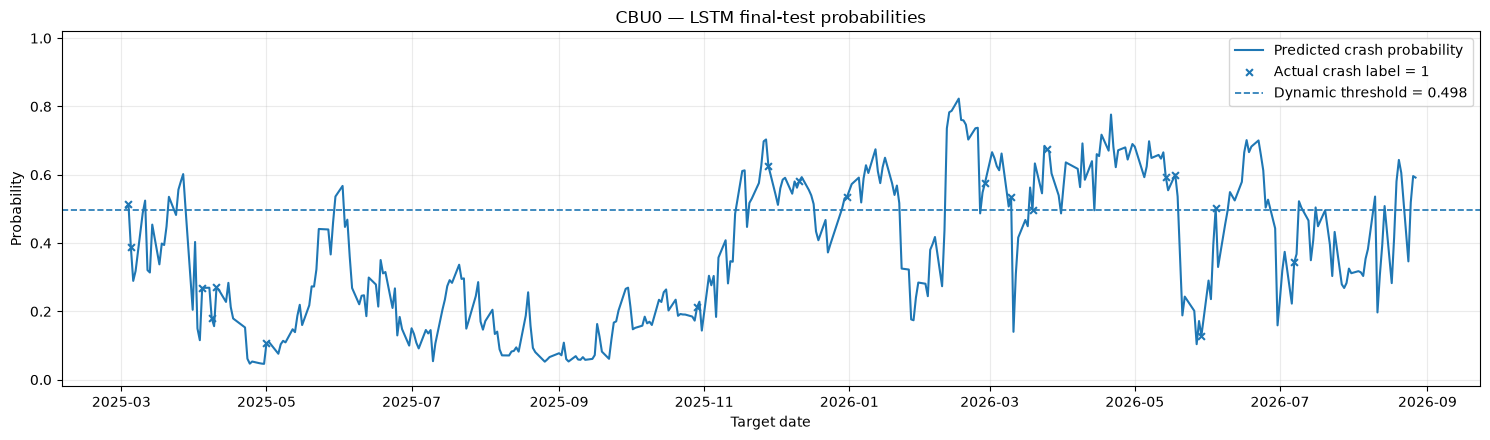

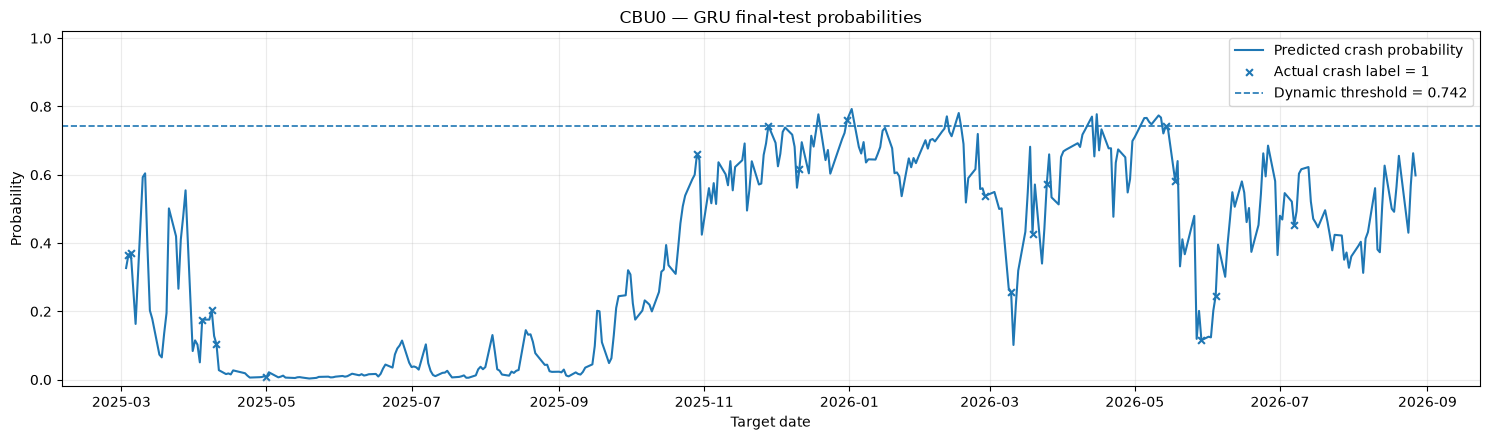

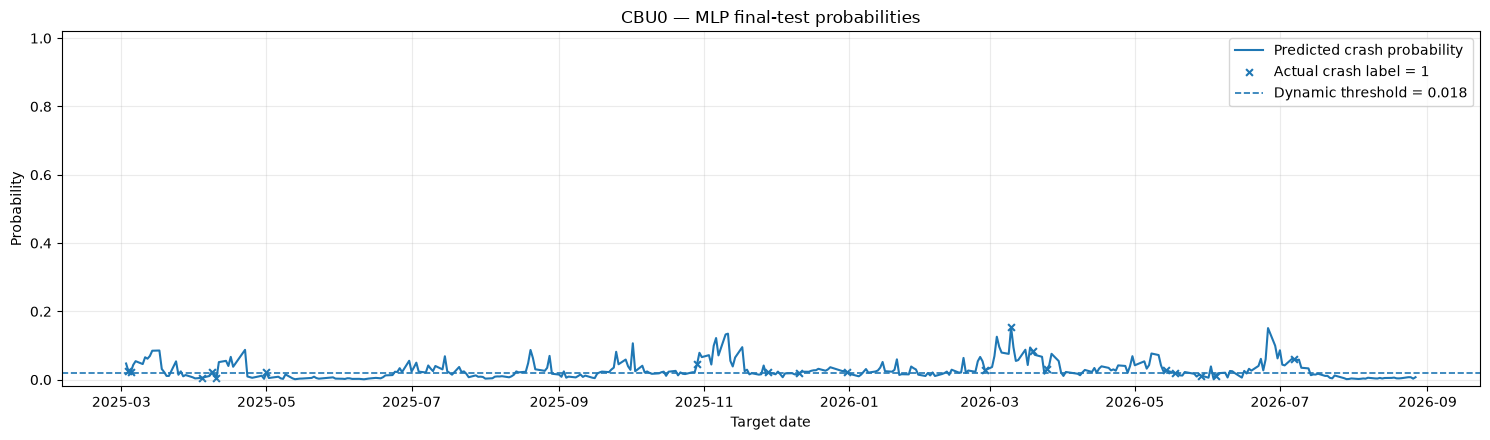

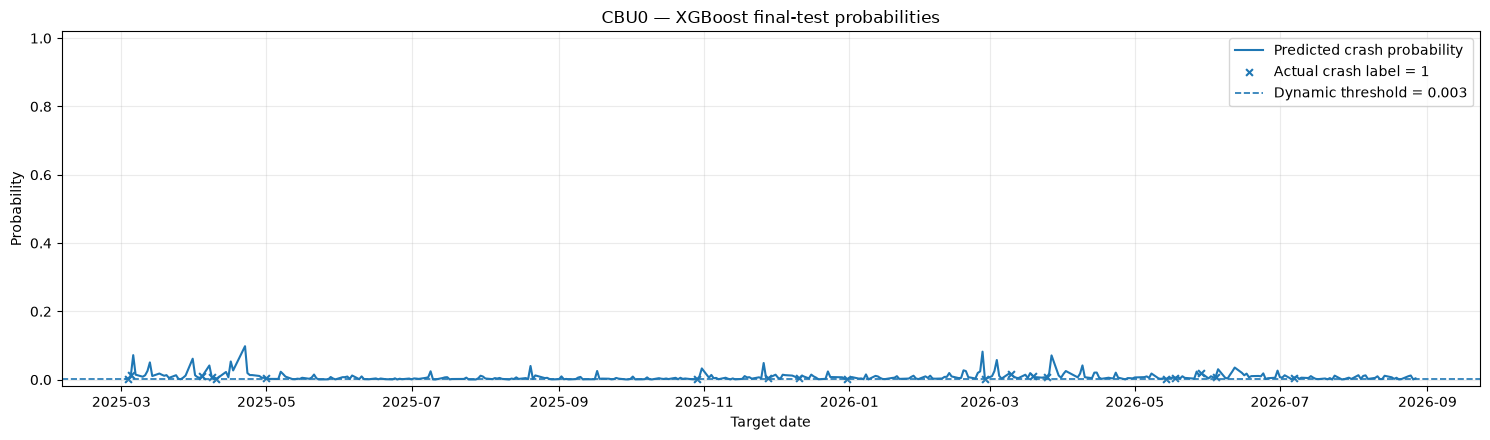

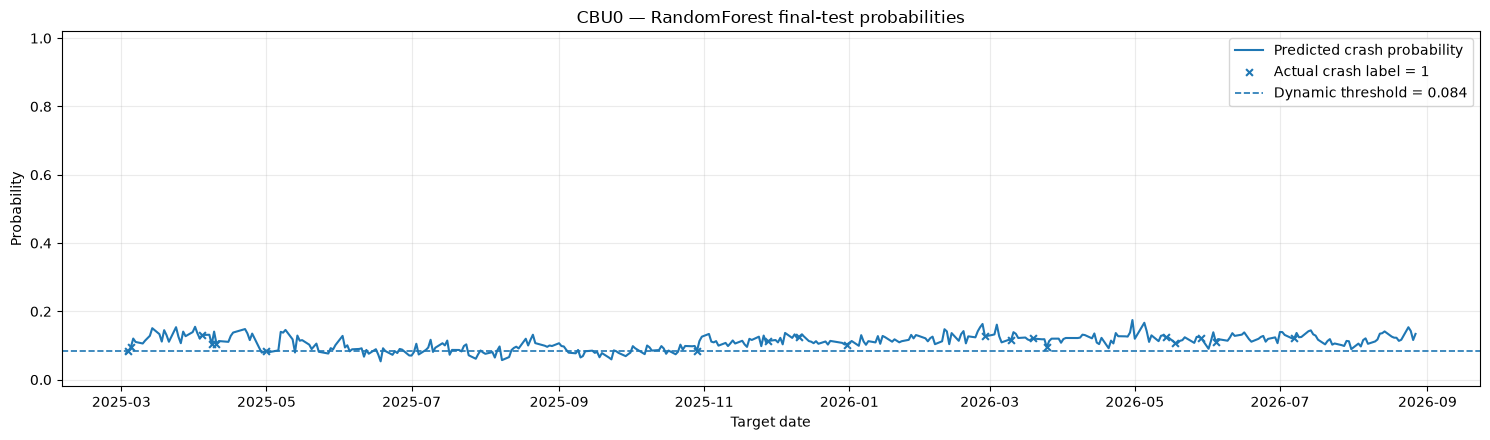

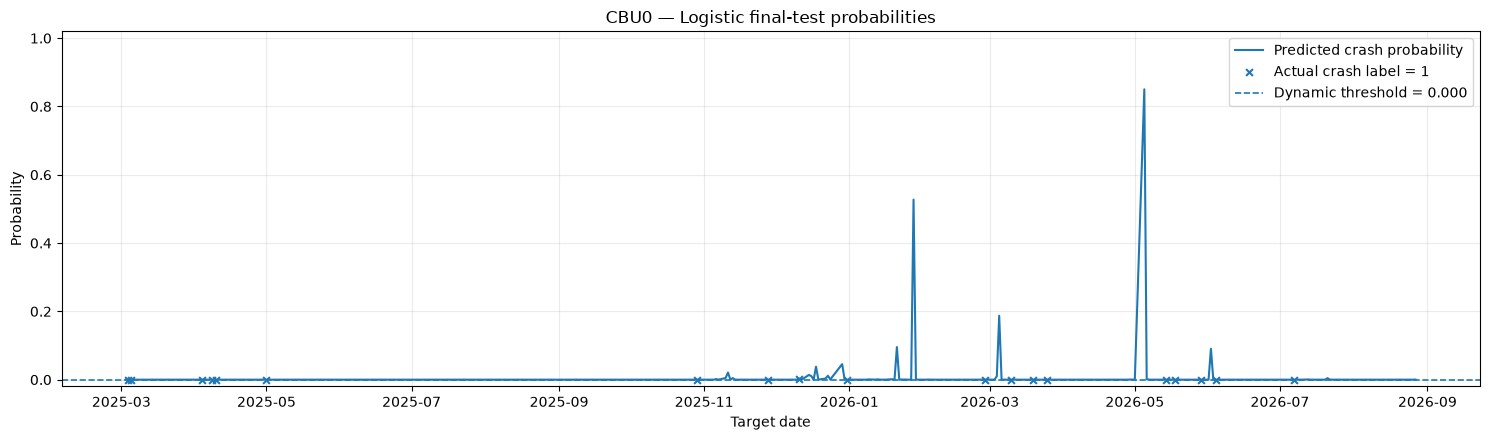

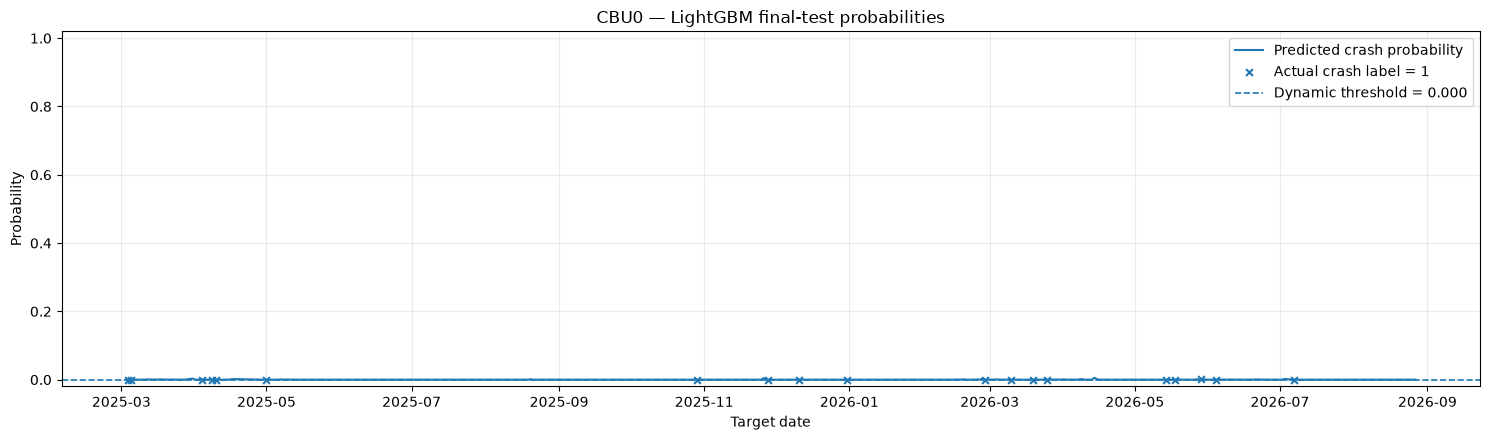

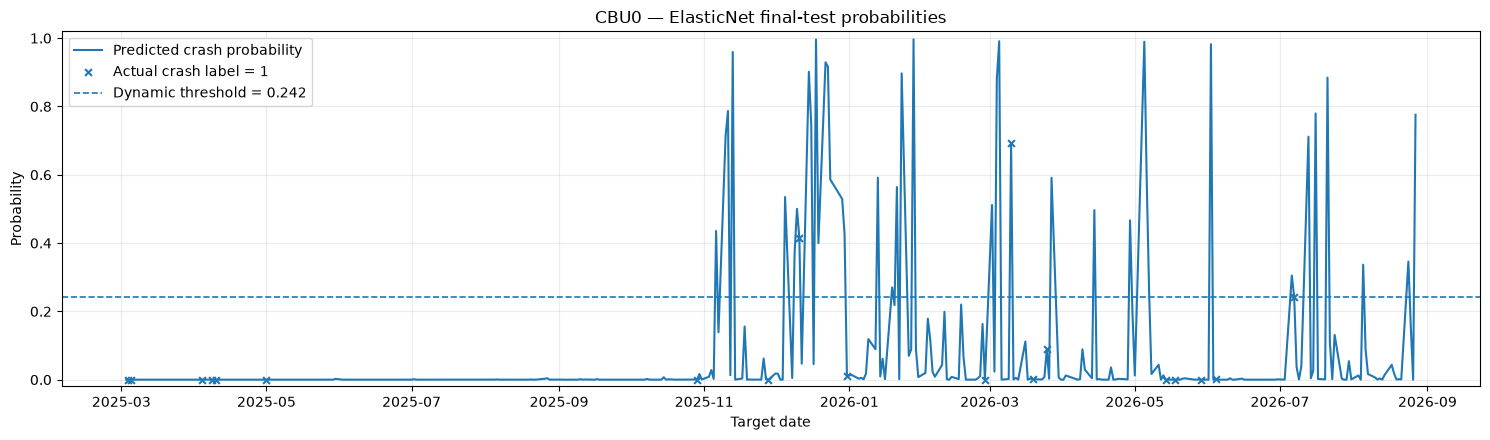

In [10]:
import matplotlib.pyplot as plt

for _, result_row in results.iterrows():
    model_name = result_row["Model"]
    probability_col = f"{model_name}_probability"
    prediction_col = f"{model_name}_prediction"
    if probability_col not in test_predictions.columns:
        continue

    plt.figure(figsize=(15, 4.5))
    plt.plot(test_predictions["date"], test_predictions[probability_col], linewidth=1.5, label="Predicted crash probability")
    positives = test_predictions["actual"] == 1
    if positives.any():
        plt.scatter(
            test_predictions.loc[positives, "date"],
            test_predictions.loc[positives, probability_col],
            s=24, marker="x", label="Actual crash label = 1",
        )
    plt.axhline(float(result_row["Threshold"]), linestyle="--", linewidth=1.2, label=f"Dynamic threshold = {result_row['Threshold']:.3f}")
    plt.title(f"{Market} — {model_name} final-test probabilities")
    plt.xlabel("Target date")
    plt.ylabel("Probability")
    plt.ylim(-0.02, 1.02)
    plt.grid(True, alpha=0.25)
    plt.legend(loc="best")
    plt.tight_layout()
    if SAVE_RESULTS:
        plt.savefig(OUTPUT_DIR / f"{Market}_finderBenchmark_{model_name.lower()}_test_probabilities.png", dpi=200)
    plt.show()